# 18. Crash Severity and Contributing Factors

How do reported factors relate to crash severity?

Primary source: https://microdata.nigerianstat.gov.ng/index.php/catalog/164

Aggregate factor counts may overlap and may not be joined to severity. No factor-specific risk without compatible records.

This notebook runs the implemented aggregate-indicator workflow. National preview outputs do not complete the primary case study.

In [1]:
from pathlib import Path
import sys
project=Path.cwd().parent if Path.cwd().name=='notebooks' else Path.cwd()
sys.path.insert(0,str(project.parents[1]))
from src.pipeline import run
status=run(project)
status

Out[0]: 
{'status': 'EXECUTED',
 'scope': 'PRIMARY_NBS_TABLES',
 'utc': '2026-11-21T18:10:37.282484+00:00',
 'rows': 666,
 'metrics': ['Reported factor: BFL',
  'Reported factor: BRD',
  'Reported factor: DAD',
  'Reported factor: DGD',
  'Reported factor: DOT',
  'Reported factor: FTQ',
  'Reported factor: MDV',
  'Reported factor: OBS',
  'Reported factor: OTHERS',
  'Reported factor: OVL',
  'Reported factor: PWR',
  'Reported factor: RTV',
  'Reported factor: SLV',
  'Reported factor: SOS',
  'Reported factor: SPV',
  'Reported factor: TBT',
  'Reported factor: UPD',
  'Reported factor: WOT'],
 'primary_case_complete': False,
 'native_bi_validated': False,
 'primary_analysis_executed': True,
 'remaining_limit': 'Factor mentions and severity are separate aggregate tables. They cannot establish factor-specific fatality risk, causal effects or individual crash mechanisms. The intended factor-by-severity analysis remains blocked by missing linked incident records.'}


,period,geography,metric,value,unit,source_url,vintage,previous_value,previous_period,absolute_change,relative_change_pct
0,2026-01-01,Abia,Reported factor: BFL,0.0,mentions,https://microdata.nigerianstat.gov.ng/index.ph...,NBS Q1 2026 release,NaN,NaN,NaN,NaN
1,2026-01-01,Adamawa,Reported factor: BFL,0.0,mentions,https://microdata.nigerianstat.gov.ng/index.ph...,NBS Q1 2026 release,NaN,NaN,NaN,NaN
2,2026-01-01,Akwa Ibom,Reported factor: BFL,4.0,mentions,https://microdata.nigerianstat.gov.ng/index.ph...,NBS Q1 2026 release,NaN,NaN,NaN,NaN
3,2026-01-01,Anambra,Reported factor: BFL,3.0,mentions,https://microdata.nigerianstat.gov.ng/index.ph...,NBS Q1 2026 release,NaN,NaN,NaN,NaN
4,2026-01-01,Bauchi,Reported factor: BFL,0.0,mentions,https://microdata.nigerianstat.gov.ng/index.ph...,NBS Q1 2026 release,NaN,NaN,NaN,NaN
5,2026-01-01,Bayelsa,Reported factor: BFL,1.0,mentions,https://microdata.nigerianstat.gov.ng/index.ph...,NBS Q1 2026 release,NaN,NaN,NaN,NaN
6,2026-01-01,Benue,Reported factor: BFL,1.0,mentions,https://microdata.nigerianstat.gov.ng/index.ph...,NBS Q1 2026 release,NaN,NaN,NaN,NaN
7,2026-01-01,Borno,Reported factor: BFL,4.0,mentions,https://microdata.nigerianstat.gov.ng/index.ph...,NBS Q1 2026 release,NaN,NaN,NaN,NaN
8,2026-01-01,Cross River,Reported factor: BFL,1.0,mentions,https://microdata.nigerianstat.gov.ng/index.ph...,NBS Q1 2026 release,NaN,NaN,NaN,NaN
9,2026-01-01,Delta,Reported factor: BFL,3.0,mentions,https://microdata.nigerianstat.gov.ng/index.ph...,NBS Q1 2026 release,NaN,NaN,NaN,NaN


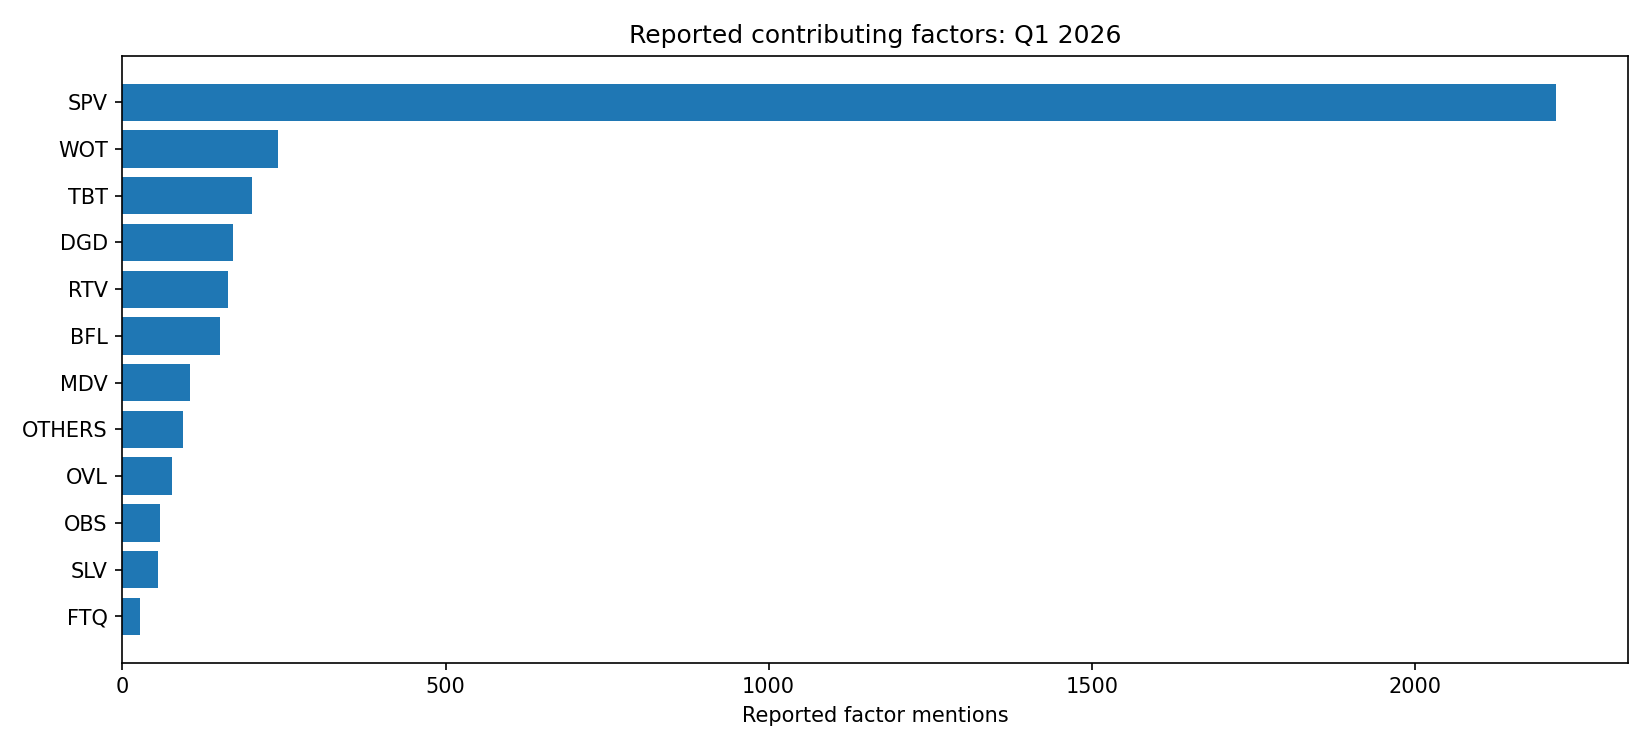

In [2]:
import pandas as pd
from IPython.display import display, Image
if status['status']=='EXECUTED':
    display(pd.read_csv(project/'outputs/analysis.csv').head(25))
    display(Image(filename=str(project/'outputs/trend.png')))
else:
    print(status['reason'])

In [3]:
display(pd.read_csv(project/'outputs/primary_analysis.csv').head(20))
print((project/'reports/RESULTS.md').read_text())

# Crash Severity and Contributing Factors: primary NBS analysis

SPV has the most recorded mentions: 2,218. Factor mentions are not mutually exclusive crash outcomes.

## Evidence and validation
22 quarters × 37 states/FCT = 814 state-quarter records. All eight state-count columns reconcile to source national totals in every quarter. Severity categories and casualty components reconcile for every state-quarter. The latest-quarter factor columns separately reconcile to published national totals. The adapter records source hashes and exact workbook rows.

## Methods
SQL is in sql/primary_analysis.sql. Source: https://microdata.nigerianstat.gov.ng/index.php/catalog/164/download/1405. Data tables and a balanced-period seasonality comparison are exported in outputs/.

![Primary chart](../outputs/trend.png)

## Limits
Factor mentions and severity are separate aggregate tables. They cannot establish factor-specific fatality risk, causal effects or individual crash mechanisms. The intended fac

,factor,reported_mentions
0,SPV,2218.0
1,WOT,240.0
2,TBT,201.0
3,DGD,171.0
4,RTV,164.0
5,BFL,151.0
6,MDV,105.0
7,OTHERS,94.0
8,OVL,77.0
9,OBS,58.0


## Interpretation
Review changes within each metric and unit separately. Changes span previous available observations, not necessarily one year. Percentage-point changes and relative percentage changes are different. No causal inference is made. Survey-design uncertainty is not estimated by this aggregate pipeline.